# 02 · Feature analysis: pre-match team performance features

**Goal of this notebook:** explore the features built by `src/feature_engineering.py`,
including what they measure, where they are missing and why, how they are distributed, and how
strongly they relate to the result. No model is trained here; that starts in commit 6.

Rebuild the feature table from the processed matches with:

```powershell
python -m src.feature_engineering
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from src.config import FIGURES_DIR
from src.feature_engineering import FEATURE_COLUMNS, FORM_WINDOWS, TEAM_FEATURES, load_features

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

features = load_features()
print(f"{len(features):,} matches x {len(FEATURE_COLUMNS)} features "
      f"({len(TEAM_FEATURES)} per team, for both the home and the away side)")
features.head(3)

11,826 matches x 50 features (25 per team, for both the home and the away side)


,match_id,season,season_start,date,home_team,away_team,result,home_goals,away_goals,home_history_matches,home_form5_ppg,home_form5_gf,home_form5_ga,home_form5_gd,home_form10_ppg,home_form10_gf,home_form10_ga,home_form10_gd,home_venue_form5_ppg,home_venue_form5_gf,home_venue_form5_ga,home_venue_form5_gd,home_venue_form10_ppg,home_venue_form10_gf,home_venue_form10_ga,home_venue_form10_gd,home_season_played,home_season_ppg,home_season_gf,home_season_ga,home_season_gd,home_prev_season_ppg,home_prev_season_gd,home_promoted,away_history_matches,away_form5_ppg,away_form5_gf,away_form5_ga,away_form5_gd,away_form10_ppg,away_form10_gf,away_form10_ga,away_form10_gd,away_venue_form5_ppg,away_venue_form5_gf,away_venue_form5_ga,away_venue_form5_gd,away_venue_form10_ppg,away_venue_form10_gf,away_venue_form10_ga,away_venue_form10_gd,away_season_played,away_season_ppg,away_season_gf,away_season_ga,away_season_gd,away_prev_season_ppg,away_prev_season_gd,away_promoted
0,0,1993-94,1993,1993-08-29,Atalanta,Cagliari,H,5,2,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
1,1,1993-94,1993,1993-08-29,Genoa,Roma,H,2,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
2,2,1993-94,1993,1993-08-29,Inter,Reggiana,H,2,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>


In [2]:
# --- Chart style (same as notebook 01) -----------------------------------------
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BLUE, AQUA, ORANGE = "#2a78d6", "#1baf7a", "#eb6834"

OUTCOMES = ["H", "D", "A"]
OUTCOME_LABELS = {"H": "Home win", "D": "Draw", "A": "Away win"}
OUTCOME_COLORS = {"H": BLUE, "D": AQUA, "A": ORANGE}


def style_axes(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def set_title(ax, title, subtitle=None, size=12):
    ax.set_title(title, loc="left", fontsize=size, color=INK, pad=26 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=9, color=INK_2, va="bottom")


def save_figure(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / name, dpi=150, facecolor=SURFACE, bbox_inches="tight")

## 1. What the features measure

Every match row holds the same set of features twice: once for the home team (`home_…`) and
once for the away team (`away_…`). All values describe the team **before kick-off**.

| Feature family | Columns (per team) | Window | At a new season | Missing when |
|---|---|---|---|---|
| History length | `history_matches` | All earlier matches in the current Serie A spell | Continues; resets after promotion | Never (0 = no history) |
| Recent form | `form5_*`, `form10_*` | Last 5 / 10 matches, any venue | Carries over from last season | Fewer than 5 / 10 earlier matches in the spell |
| Venue form | `venue_form5_*`, `venue_form10_*` | Last 5 / 10 **home** matches for the home team, **away** matches for the away team | Carries over from last season | Fewer than 5 / 10 earlier matches at that venue |
| Season to date | `season_played`, `season_ppg`, `season_gf`, `season_ga`, `season_gd` | All earlier matches this season | Restarts at zero | First match of the season |
| Last season | `prev_season_ppg`, `prev_season_gd`, `promoted` | Whole previous season | — | Team was not in Serie A last season |

Each form family has four per-game averages: `ppg` (points per game: 3 for a win, 1 for a draw),
`gf` (goals scored), `ga` (goals conceded) and `gd` (goal difference).

**Leakage rules, enforced in code and by unit tests:**

- A match's own score is never used. Each feature looks up the team's state from a
  **strictly earlier date**, so matches played on the same day cannot see each other's results.
- A *spell* is a run of consecutive Serie A seasons. A team that comes up from Serie B starts with
  no history, because its Serie B matches are not in the data.
- The targets (`result`, `home_goals`, `away_goals`) are copied unchanged from `matches.csv`.

## 2. Missing history

Missing values are deliberate: they mark matches where a team doesn't yet have enough history
for that feature. They are never filled in with zeros or with a shorter window.

In [3]:
families = {
    "History length": ["history_matches"],
    "Form, last 5": [f"form5_{s}" for s in ("ppg", "gf", "ga", "gd")],
    "Form, last 10": [f"form10_{s}" for s in ("ppg", "gf", "ga", "gd")],
    "Venue form, last 5": [f"venue_form5_{s}" for s in ("ppg", "gf", "ga", "gd")],
    "Venue form, last 10": [f"venue_form10_{s}" for s in ("ppg", "gf", "ga", "gd")],
    "Season to date": ["season_ppg", "season_gf", "season_ga", "season_gd"],
    "Last season": ["prev_season_ppg", "prev_season_gd"],
}
# A family is missing for a match when either team lacks it
missing = pd.Series({
    family: features[[f"{side}_{c}" for side in ("home", "away") for c in cols]].isna().any(axis=1).mean()
    for family, cols in families.items()
}).sort_values()

complete = features[FEATURE_COLUMNS].notna().all(axis=1)
complete_by_season = complete.groupby(features["season"]).mean()

missing.rename("share of matches missing for at least one team").to_frame().style.format("{:.1%}")

,share of matches missing for at least one team
History length,0.0%
Season to date,2.8%
"Form, last 5",4.8%
"Form, last 10",9.5%
"Venue form, last 5",9.5%
"Venue form, last 10",19.0%
Last season,34.2%


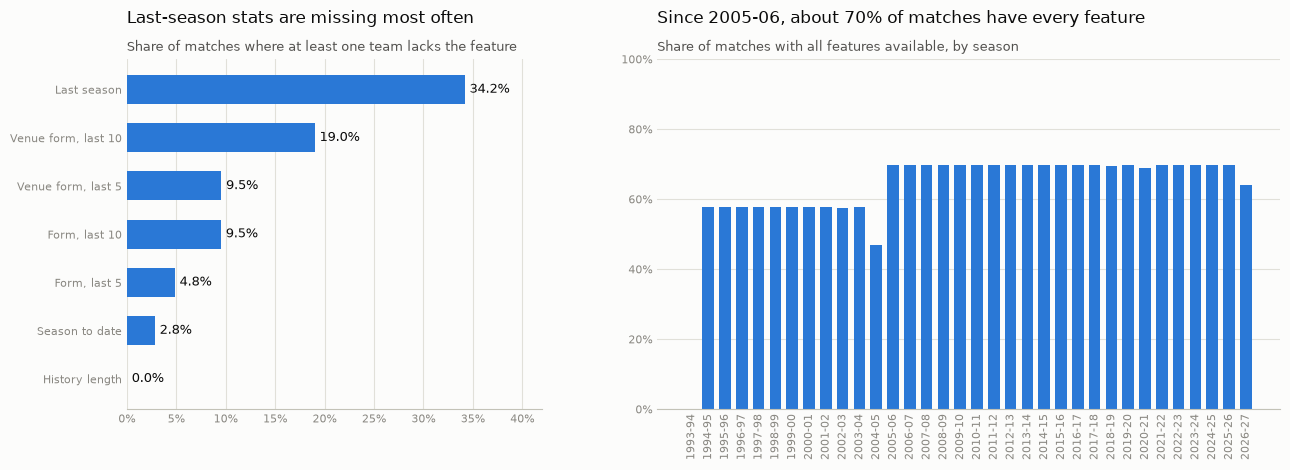

In [4]:
fig, (ax_fam, ax_season) = plt.subplots(
    1, 2, figsize=(13, 4.8), facecolor=SURFACE, gridspec_kw={"width_ratios": [1, 1.5]}
)

y = np.arange(len(missing))
ax_fam.barh(y, missing.values, color=BLUE, height=0.6)
for yi, share in zip(y, missing.values):
    ax_fam.text(share + 0.005, yi, f"{share:.1%}", va="center", fontsize=9, color=INK)
ax_fam.set_yticks(y, missing.index, fontsize=9, color=INK_2)
ax_fam.set_xlim(0, 0.42)
ax_fam.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
style_axes(ax_fam, grid="x")
set_title(ax_fam, "Last-season stats are missing most often",
          "Share of matches where at least one team lacks the feature")

x = np.arange(len(complete_by_season))
ax_season.bar(x, complete_by_season.values, color=BLUE, width=0.7)
ax_season.set_xticks(x, complete_by_season.index, rotation=90)
ax_season.set_ylim(0, 1)
ax_season.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
style_axes(ax_season)
set_title(ax_season, "Since 2005-06, about 70% of matches have every feature",
          "Share of matches with all features available, by season")

fig.tight_layout(w_pad=4)
save_figure(fig, "06_feature_missingness.png")
plt.show()

In [5]:
# Why last-season stats are missing: promoted teams (plus 1993-94, which has no earlier season)
involves_promoted = features["home_promoted"].fillna(False) | features["away_promoted"].fillna(False)
first_season = features["season_start"] == features["season_start"].min()
print(f"Matches involving a promoted team: {involves_promoted.mean():.1%}")
print(f"Matches in the first season (1993-94): {first_season.mean():.1%}")
print(f"Last-season stats missing for either team: "
      f"{features[['home_prev_season_ppg', 'away_prev_season_ppg']].isna().any(axis=1).mean():.1%}")

Matches involving a promoted team: 31.6%
Matches in the first season (1993-94): 2.6%
Last-season stats missing for either team: 34.2%


**Interpretation**

- **1993-94** is the first season in the data, so nothing earlier is known and no match there has
  a complete feature set.
- After that, matches miss something almost entirely because **promoted teams** have no Serie A
  season to look back on. In the 20-team era, 3 promoted teams take part in up to 3 of the 10
  matches every matchday, so about **70% of matches** are complete. In the 18-team 1990s there
  were 4 promoted teams, and only about 58% are complete. Across all seasons, **34%** of matches
  lack last-season stats for at least one team.
- Form windows fill up quickly. `form5` is missing in under 5% of matches and `venue_form10`,
  which needs 10 home or 10 away games, in about 19%.
- **Open decision for commit 6:** dropping every incomplete match would throw away about a third of the
  data, and it would remove promoted teams, which are systematically weaker (section 4).
  The options are to leave out last-season features, or to fill them with a typical
  promoted-team value and keep the `promoted` flag. This notebook only documents the gap; it
  doesn't fill it.

## 3. Feature distributions

The charts show the **home team's** features; the away team's look the same, since every team
appears on both sides. The last panel compares venue form directly.

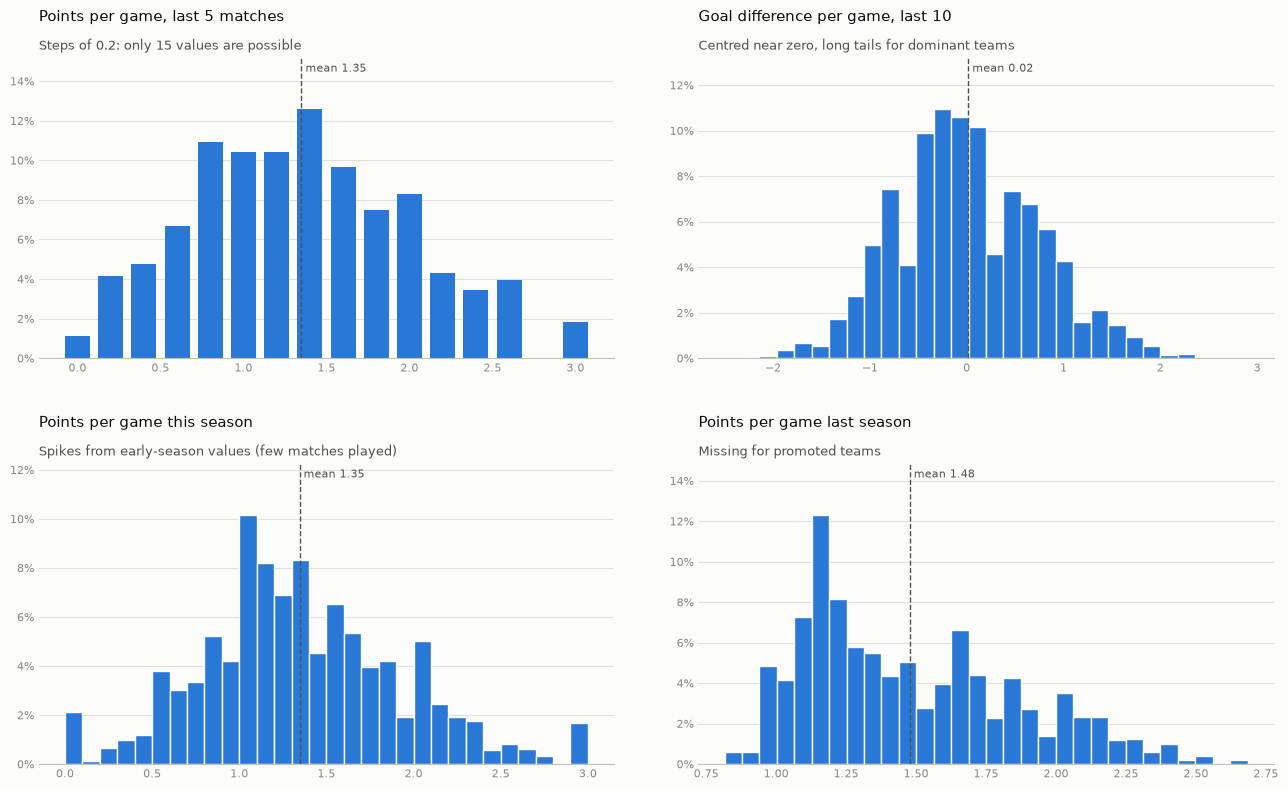

,count,mean,std,min,50%,max
home_form5_ppg,11502.0,1.35,0.66,0.00,1.40,3.00
home_form10_gd,11184.0,0.02,0.74,-2.50,0.00,2.90
home_season_ppg,11498.0,1.35,0.58,0.00,1.30,3.00
home_prev_season_ppg,9514.0,1.48,0.38,0.82,1.39,2.68


In [6]:
panels = [
    ("home_form5_ppg", "Points per game, last 5 matches", "Steps of 0.2: only 15 values are possible"),
    ("home_form10_gd", "Goal difference per game, last 10", "Centred near zero, long tails for dominant teams"),
    ("home_season_ppg", "Points per game this season", "Spikes from early-season values (few matches played)"),
    ("home_prev_season_ppg", "Points per game last season", "Missing for promoted teams"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), facecolor=SURFACE)
for ax, (col, title, subtitle) in zip(axes.ravel(), panels):
    values = features[col].dropna()
    if col == "home_form5_ppg":
        counts = values.round(1).value_counts(normalize=True).sort_index()
        ax.bar(counts.index, counts.values, width=0.15, color=BLUE)
    else:
        ax.hist(values, bins=30, color=BLUE, edgecolor=SURFACE, linewidth=1,
                weights=np.full(len(values), 1 / len(values)))
    top = ax.get_ylim()[1] * 1.15
    ax.set_ylim(0, top)
    ax.axvline(values.mean(), color=INK_2, linewidth=1, linestyle="--")
    ax.text(values.mean(), top * 0.98, f" mean {values.mean():.2f}", fontsize=8, color=INK_2, va="top")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    style_axes(ax)
    set_title(ax, title, subtitle, size=10.5)

fig.tight_layout(h_pad=3, w_pad=4)
save_figure(fig, "07_feature_distributions.png")
plt.show()

summary_cols = ["home_form5_ppg", "home_form10_gd", "home_season_ppg", "home_prev_season_ppg"]
features[summary_cols].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2)

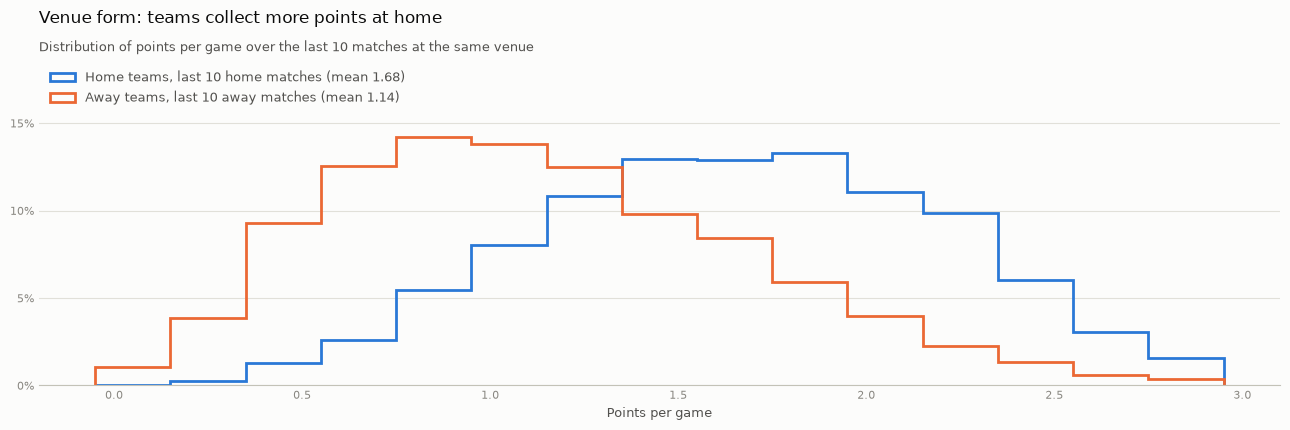

In [7]:
# Venue form: home teams in their home games vs away teams in their away games.
# Values come in steps of 0.1, so each bin of width 0.2 covers exactly two possible values.
fig, ax = plt.subplots(figsize=(13, 4.4), facecolor=SURFACE)
bins = np.arange(-0.05, 3.1, 0.2)
for col, label, color in [("home_venue_form10_ppg", "Home teams, last 10 home matches", BLUE),
                          ("away_venue_form10_ppg", "Away teams, last 10 away matches", ORANGE)]:
    values = features[col].dropna()
    ax.hist(values, bins=bins, histtype="step", linewidth=2, color=color,
            label=f"{label} (mean {values.mean():.2f})",
            weights=np.full(len(values), 1 / len(values)))
ax.set_xlabel("Points per game", color=INK_2, fontsize=9)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylim(0, ax.get_ylim()[1] * 1.25)
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="upper left")
style_axes(ax)
set_title(ax, "Venue form: teams collect more points at home",
          "Distribution of points per game over the last 10 matches at the same venue")
fig.tight_layout()
save_figure(fig, "08_venue_form.png")
plt.show()

**Interpretation**

- `form5_ppg` is **discrete**: five matches give 0 to 15 points (14 is impossible), so it takes
  only 15 values in steps of 0.2. `form10` is smoother, but it needs twice as much history
  before it becomes available.
- Season-to-date averages are noisy early in the season. After one match the value can only be
  0, 1 or 3, so `season_played` is worth keeping next to them as a measure of reliability.
- Venue form captures home advantage inside the features: on average, home teams have taken
  **1.68** points per game in their last 10 home matches, while away teams have taken **1.14** in
  their last 10 away matches.
- Feature scales differ (points per game run from 0 to 3, `history_matches` runs into the
  hundreds). Linear models will need **standardised** inputs; tree models will not.

## 4. Promoted teams

Promoted teams are where most features are missing, so it matters whether they behave
differently. The first season is excluded, because promotion is unknown there.

In [8]:
known = features[features["home_promoted"].notna()]
situation = np.select(
    [known["home_promoted"] & ~known["away_promoted"],
     ~known["home_promoted"] & known["away_promoted"],
     ~known["home_promoted"] & ~known["away_promoted"]],
    ["Promoted team at home", "Promoted team away", "Neither team promoted"],
    default="Both teams promoted",
)
by_situation = (pd.crosstab(situation, known["result"], normalize="index")[OUTCOMES]
                .reindex(["Neither team promoted", "Promoted team at home", "Promoted team away"]))
by_situation["matches"] = pd.Series(situation).value_counts()
by_situation.style.format({o: "{:.1%}" for o in OUTCOMES} | {"matches": "{:,}"})

result,H,D,A,matches
row_0,,,,
Neither team promoted,45.1%,27.1%,27.9%,"7,785"
Promoted team at home,33.1%,27.6%,39.3%,"1,729"
Promoted team away,58.9%,26.3%,14.7%,"1,729"


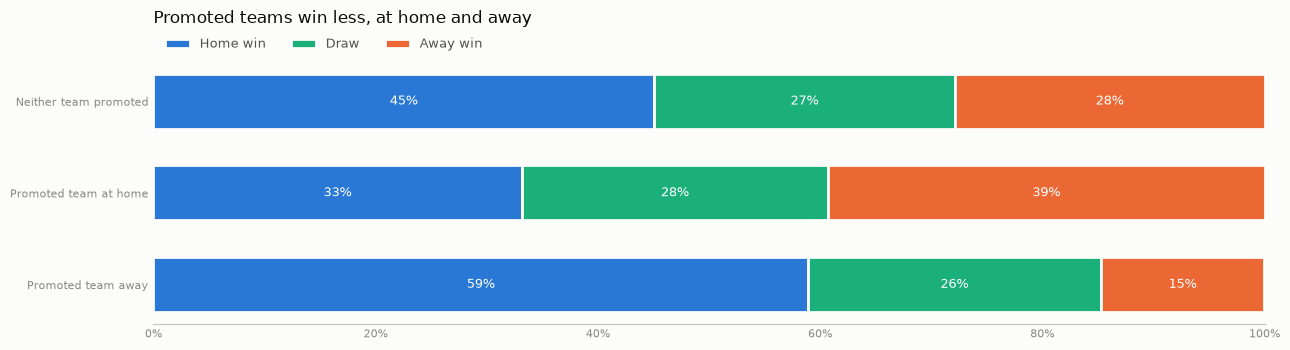

In [9]:
fig, ax = plt.subplots(figsize=(13, 3.6), facecolor=SURFACE)
y = np.arange(len(by_situation))[::-1]
left = np.zeros(len(by_situation))
for outcome in OUTCOMES:
    shares = by_situation[outcome].values
    ax.barh(y, shares, left=left, color=OUTCOME_COLORS[outcome], height=0.6,
            edgecolor=SURFACE, linewidth=2, label=OUTCOME_LABELS[outcome])
    for yi, l, s in zip(y, left, shares):
        ax.text(l + s / 2, yi, f"{s:.0%}", ha="center", va="center", fontsize=9,
                color="#ffffff")
    left += shares
ax.set_yticks(y, by_situation.index, fontsize=9, color=INK_2)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(frameon=False, fontsize=9, labelcolor=INK_2, ncols=3, loc="lower left",
          bbox_to_anchor=(0, 1.0))
style_axes(ax, grid=None)
ax.set_title("Promoted teams win less, at home and away", loc="left", fontsize=12, color=INK, pad=28)
fig.tight_layout()
save_figure(fig, "09_promoted_teams.png")
plt.show()

**Interpretation**

- When a promoted team plays at home, the home-win share falls from **45%** (neither team
  promoted) to **33%**, and away wins become the most likely result. When a promoted team
  visits, the home team wins **59%** of the time and the visitor only 15%.
- Being promoted is therefore **informative in itself**, which is why the `promoted` flag is
  kept as a feature. It also means simply dropping matches with missing last-season stats would
  bias the training data towards matches between established teams.

## 5. How strongly do the features relate to the result?

A useful feature should separate stronger teams from weaker ones. For each feature we take the
**difference between the home and the away team** and compare it with the match outcome.
This is only exploration. The model itself is built in commit 6.

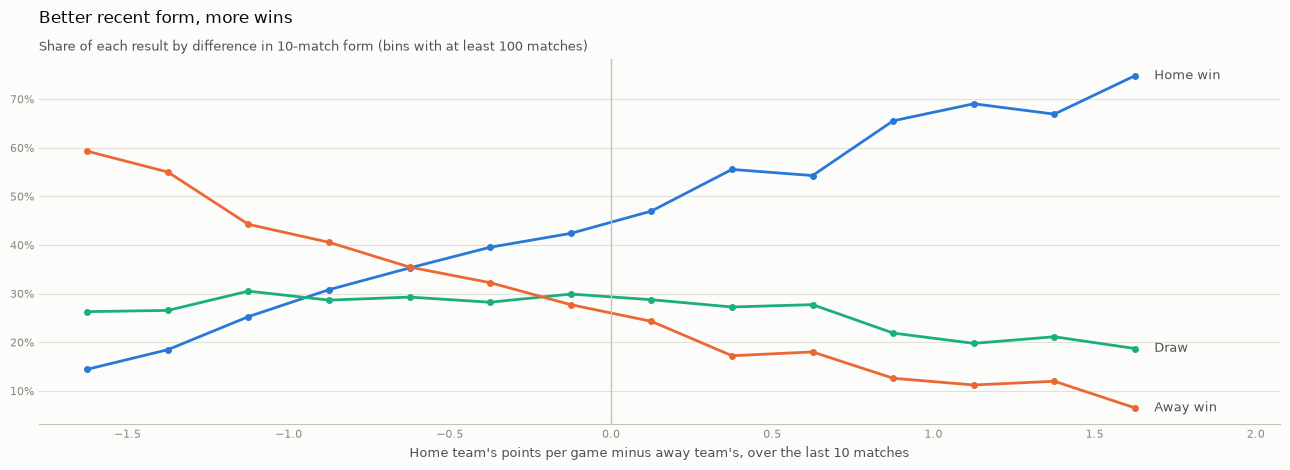

result,H,D,A,matches
row_0,,,,
"(-1.75, -1.5]",14.4%,26.3%,59.3%,194
"(-1.5, -1.25]",18.5%,26.5%,55.0%,260
"(-1.25, -1.0]",25.3%,30.5%,44.2%,590
"(-1.0, -0.75]",30.8%,28.7%,40.5%,698
"(-0.75, -0.5]",35.3%,29.3%,35.4%,"1,151"
"(-0.5, -0.25]",39.5%,28.2%,32.2%,"1,070"
"(-0.25, 0.0]",42.4%,29.9%,27.7%,"1,739"
"(0.0, 0.25]",47.0%,28.7%,24.3%,"1,103"
"(0.25, 0.5]",55.5%,27.2%,17.2%,"1,347"


In [10]:
diff = features["home_form10_ppg"] - features["away_form10_ppg"]
bins = np.arange(-2.0, 2.01, 0.25)
binned = pd.cut(diff, bins)
outcome_by_bin = pd.crosstab(binned, features["result"], normalize="index")[OUTCOMES]
outcome_by_bin["matches"] = binned.value_counts()
outcome_by_bin = outcome_by_bin[outcome_by_bin["matches"] >= 100]  # skip thin bins

fig, ax = plt.subplots(figsize=(13, 4.8), facecolor=SURFACE)
centres = [interval.mid for interval in outcome_by_bin.index]
for outcome in OUTCOMES:
    values = outcome_by_bin[outcome].values
    ax.plot(centres, values, color=OUTCOME_COLORS[outcome], linewidth=2, marker="o", markersize=4)
    ax.text(centres[-1] + 0.06, values[-1], OUTCOME_LABELS[outcome], va="center", fontsize=9,
            color=INK_2)
ax.axvline(0, color=BASELINE, linewidth=1)
ax.set_xlabel("Home team's points per game minus away team's, over the last 10 matches",
              color=INK_2, fontsize=9)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlim(min(centres) - 0.15, max(centres) + 0.45)
style_axes(ax)
set_title(ax, "Better recent form, more wins",
          "Share of each result by difference in 10-match form (bins with at least 100 matches)")
fig.tight_layout()
save_figure(fig, "10_form_difference_vs_result.png")
plt.show()

outcome_by_bin.style.format({o: "{:.1%}" for o in OUTCOMES} | {"matches": "{:,}"})

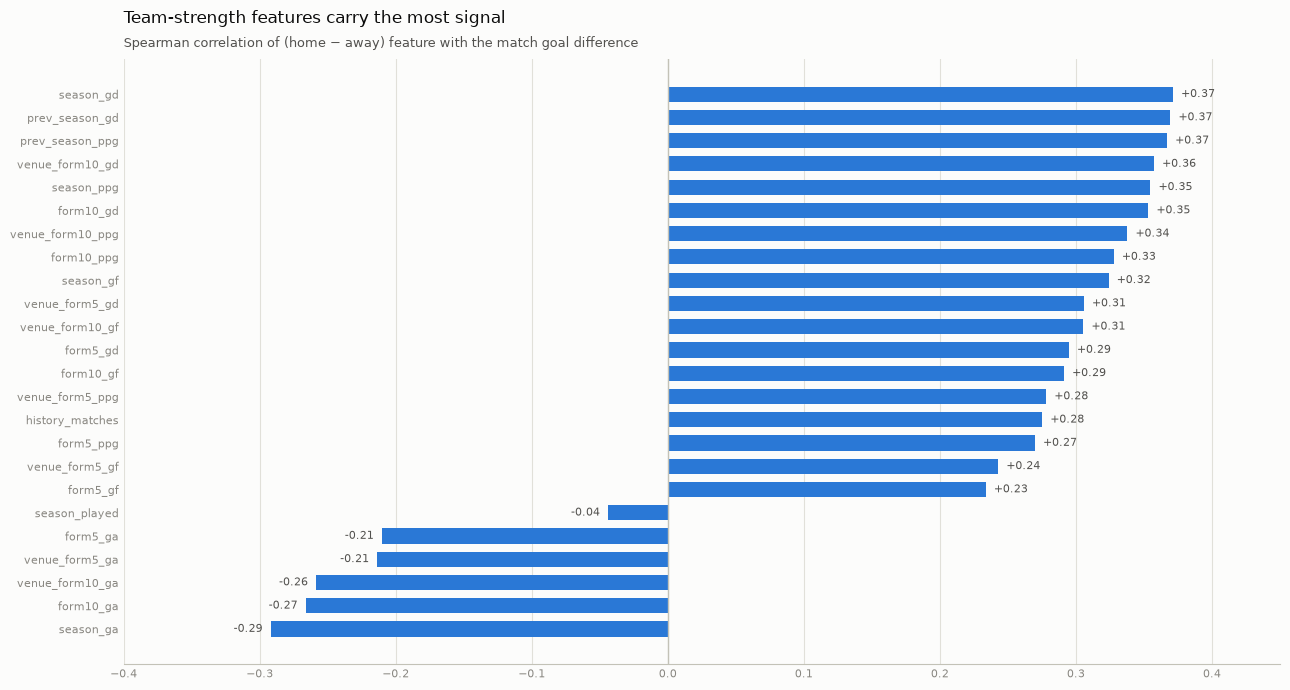

,spearman,available
feature,,
season_gd,+0.371,97.2%
prev_season_gd,+0.369,65.8%
prev_season_ppg,+0.367,65.8%
venue_form10_gd,+0.357,81.0%
season_ppg,+0.355,97.2%
form10_gd,+0.353,90.5%
venue_form10_ppg,+0.338,81.0%
form10_ppg,+0.328,90.5%
season_gf,+0.324,97.2%


In [11]:
# Rank correlation between each home-minus-away feature difference and the match goal
# difference. Spearman is used because many features are discrete or skewed.
goal_diff = (features["home_goals"] - features["away_goals"]).astype(float)
numeric = [name for name in TEAM_FEATURES if name != "promoted"]
signal = pd.DataFrame([
    {
        "feature": name,
        "spearman": (features[f"home_{name}"] - features[f"away_{name}"]).corr(goal_diff, method="spearman"),
        "available": (features[[f"home_{name}", f"away_{name}"]].notna().all(axis=1)).mean(),
    }
    for name in numeric
]).sort_values("spearman")

fig, ax = plt.subplots(figsize=(13, 7), facecolor=SURFACE)
y = np.arange(len(signal))
ax.barh(y, signal["spearman"], color=BLUE, height=0.65)
for yi, value in zip(y, signal["spearman"]):
    ax.text(value + (0.006 if value >= 0 else -0.006), yi, f"{value:+.2f}", va="center",
            ha="left" if value >= 0 else "right", fontsize=8, color=INK_2)
ax.set_yticks(y, signal["feature"], fontsize=9, color=INK_2)
ax.axvline(0, color=BASELINE, linewidth=1)
ax.set_xlim(-0.4, 0.45)
style_axes(ax, grid="x")
set_title(ax, "Team-strength features carry the most signal",
          "Spearman correlation of (home − away) feature with the match goal difference")
fig.tight_layout()
save_figure(fig, "11_feature_signal.png")
plt.show()

signal.sort_values("spearman", ascending=False).set_index("feature").style.format(
    {"spearman": "{:+.3f}", "available": "{:.1%}"})

**Interpretation**

- The relationship is clear and **monotonic**. When the home team's recent form is much better,
  home wins dominate; when it is much worse, away wins take over. **Draws stay between about 19%
  and 31% across the whole range**, which confirms that draws will be the hardest outcome to
  predict.
- The strongest features measure **sustained team strength**: goal difference and points per game
  this season and last season, and form over 10 matches. Each correlates at about +0.35 with the
  goal margin.
- Longer windows beat shorter ones (`form10` > `form5`), and goal difference beats points:
  goal difference is less affected by luck than wins and draws.
- `history_matches` also carries signal: long-established Serie A clubs tend to be the stronger
  ones. `season_played` carries almost none on its own, as expected, because it only says how
  far into the season the match is.
- Goals conceded (`ga`) features are negative, as expected: conceding more than the opponent is bad.

## 6. Redundancy between features

Many features describe the same underlying quality from slightly different angles.
The heatmap shows correlations between the home team's own features.

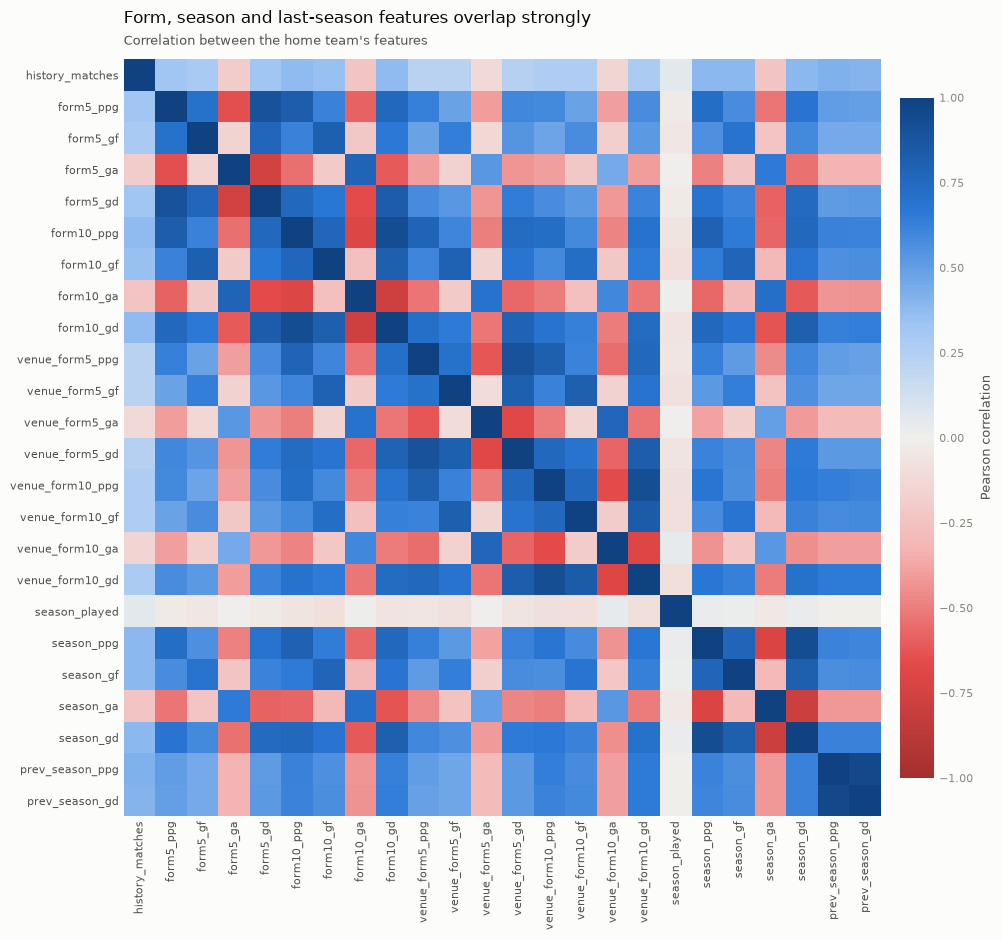

In [12]:
corr_cols = [f"home_{name}" for name in numeric]
corr = features[corr_cols].corr()
labels = [c.removeprefix("home_") for c in corr_cols]

diverging = LinearSegmentedColormap.from_list(
    "diverging", ["#a3302f", "#e34948", "#f4b4b3", "#f0efec", "#9ec5f4", "#2a78d6", "#104281"]
)
fig, ax = plt.subplots(figsize=(11, 9.5), facecolor=SURFACE)
image = ax.imshow(corr.values, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=8, color=INK_2)
ax.set_yticks(range(len(labels)), labels, fontsize=8, color=INK_2)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
cbar = fig.colorbar(image, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("Pearson correlation", color=INK_2, fontsize=9)
cbar.ax.tick_params(colors=MUTED, labelsize=8, length=0)
cbar.outline.set_visible(False)
set_title(ax, "Form, season and last-season features overlap strongly",
          "Correlation between the home team's features")
fig.tight_layout()
save_figure(fig, "12_feature_correlation.png")
plt.show()

In [13]:
pairs = [("form5_ppg", "form10_ppg"), ("form10_ppg", "form10_gd"), ("form10_gd", "season_gd"),
         ("season_gd", "prev_season_gd"), ("form10_ppg", "venue_form10_ppg")]
pd.Series({f"{a} vs {b}": corr.loc[f"home_{a}", f"home_{b}"] for a, b in pairs},
          name="correlation").round(2).to_frame()

,correlation
form5_ppg vs form10_ppg,0.82
form10_ppg vs form10_gd,0.92
form10_gd vs season_gd,0.81
season_gd vs prev_season_gd,0.62
form10_ppg vs venue_form10_ppg,0.72


**Interpretation**

- `gd` is **exactly** `gf − ga` for every window, so the three are perfectly linearly dependent.
  A linear model should use either `gd` or `gf` and `ga`, not all three.
- Points per game and goal difference over the same window are highly correlated, as are form
  over 5 and 10 matches. This redundancy doesn't hurt tree-based models much, but for Logistic
  Regression it inflates coefficient uncertainty and argues for a smaller, cleaner feature set
  (or regularisation).

## Key findings

| Finding | Implication for modelling (commit 6 onwards) |
|---|---|
| 50 leakage-safe features, 25 per team, tested to use only strictly earlier dates | Safe to train on directly |
| 34% of matches lack last-season stats (mostly promoted teams) | Decide to drop those features or fill them for promoted teams; don't drop the matches |
| Promoted teams win clearly less | Keep the `promoted` flag |
| Sustained-strength features (season and last-season goal difference, form over 10 matches) carry the most signal | Prioritise them; home-minus-away differences are a natural input |
| Draws stay at about 19–31% whatever the form gap | Expect the draw class to be hardest |
| Strong redundancy between features; `gd = gf − ga` | Use a compact set or regularisation for Logistic Regression |
| Features use very different scales | Standardise for linear models |

## Next steps

- **Commit 6:** first Logistic Regression model. Choose the feature set, handle the
  promoted-team gap, train on earlier seasons and evaluate on the most recent ones against the
  45% "always home win" baseline.